# Supervised Models

**Goal:** Predict whether an issue-week is a **narrative shift** (label = 1) or not (label = 0) using features from the unsupervised topic models and tweet volume.

1. [New Features](#build-the-new-features)
2. [Cross-Validation](#week-based-cross-validation-folds)
3. [Features, Models, and Baselines](#features-models-and-baselines)
4. [Tuning](#tuning-the-models)
5. [Ablation](#ablation-which-feature-groups-help)
6. [Feature importance](#feature-importance-grouped-permutation-importance)
7. [Sensitivity analysis](#sensitivity-analysis)
8. [Tradeoffs](#tradeoffs)
9. [Failure Analysis](#failure-analysis)

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    average_precision_score, f1_score, precision_score, recall_score,
)

RANDOM_SEED = 42

In [2]:
df = pd.read_csv("../DataFiles/supervised_model_table.csv")
print(len(df))

# Week 0 has no label so we drop it
df = df.dropna(subset=["label"])
df["label"] = df["label"].astype(int)
print(len(df))

155
150


# Build the new features

**log_orig_per_day:** Tweets per day for this issue. On a log scale so weeks with missing days don't look like quiet weeks.

**shift_minus_noise:** How far the shift score is above the noise floor. We're focusing on the change above the noise floor.

**noise_missing:** We'll identify the rows missing a noise floor (1: no noise floor) for the model so  we know which ones the imputer is guessing b/c these are not normal weeks. These weeks didn't have enough tweets to get a noise floor.

**Lag features - lag1_shift, lag2_shift:** This issue's shift score 1 and 2 weeks earlier. Lags can help the model learn patterns.

**shift_zscore:** How different this week's shift score is compared with the earlier weeks in this issue. The z-score only looks at its past weeks to prevent data leakage. This required clipping because the early weeks only had a few past weeks of shift scores to compare to. Some of those weeks happened to have very similar shift scores which made their past_std very small, and dividing by a very small number makes extreme z-scores that aren't meaningful (for example, immigration week 4 scored −11.67). So I capped z-scores at −3 and +3.

In [3]:
def prep_table(df: pd.DataFrame) -> pd.DataFrame:
    """Sort rows, then add the new features. Returns a new table."""

    df = df.sort_values(["issue", "week"]).copy()
    df["week_idx"] = df["week"]

    df["log_orig_per_day"] = np.log(df["orig_tweet_count"] / df["days_with_data"])
    df["shift_minus_noise"] = df["shift_score"] - df["noise_floor"]
    df["noise_missing"] = df["noise_floor"].isna().astype(int)

    # Lags: groupby("issue") so each issue's history is separate
    by_issue = df.groupby("issue")["shift_score"]
    df["lag1_shift"] = by_issue.shift(1)
    df["lag2_shift"] = by_issue.shift(2)

    # Z-score: use at least 3 past weeks so the average makes sense
    past = df.groupby("issue")["lag1_shift"]
    past_mean = past.transform(lambda s: s.expanding(min_periods=3).mean())
    past_std = past.transform(lambda s: s.expanding(min_periods=3).std())
    df["shift_zscore"] = (df["shift_score"] - past_mean) / past_std

    # Cap z-scores at -3 and +3 b/c dividing by past_std makes extreme values
    df["shift_zscore"] = df["shift_zscore"].clip(lower=-3, upper=3)

    return df

We'll drop rows with no shift score or lags, like the first weeks of each issue and some of the abortion weeks.

In [4]:
rows_before = len(df)
df = prep_table(df)
df = df.dropna(subset=["shift_score", "lag1_shift", "lag2_shift"]).reset_index(drop=True)

print(f"{len(df)}")
print(f"{rows_before - len(df)} rows dropped")
print(f"Shift rate: {df['label'].mean():.1%}")
print("Blanks we'll fill in later with imputer:")
print(df[["shift_minus_noise", "shift_zscore"]].isna().sum())

137
13 rows dropped
Shift rate: 16.1%
Blanks we'll fill in later with imputer:
shift_minus_noise    12
shift_zscore          5
dtype: int64


In [5]:
df.groupby("label")[["shift_score", "shift_minus_noise", "shift_zscore"]].mean().round(3)

,shift_score,shift_minus_noise,shift_zscore
label,,,
0,0.308,-0.009,-0.15
1,0.315,0.044,-0.05


### Do shift weeks have higher scores on average?
Not very much. None of the scores have clearly higher shift weeks over normal weeks. Shift_minus_noise improves the shift week scores the most though.

The original shift_score is almost the same in shift weeks (0.315) and normal weeks (0.308). The noise floor is the change we'd expect from random variation from one week to the next. After subtracting the noise, normal weeks score around zero (−0.009), meaning no more change than chance, and shift weeks score above zero (+0.044), so they have more change than chance. We also calculated a past z-score (shift_zscore), which shows how different a week is compared to that issue's earlier weeks. In the first few weeks, only three past weeks were available, so a few scores came out with high scores. We capped the z-score at ±3 so those weeks wouldn't distort the results. After capping, shift weeks are slightly more separated from normal weeks (−0.05 vs. −0.15). The models need to combine several features because the scores do not separate the label very much.

# Week-based cross-validation folds

We split the data by week, train each fold on earlier weeks, and test on later weeks. The training window grows with each fold, so the model never sees the future.

We skip one week between training and testing (gap=1) to be careful, because neighboring weeks tend to look alike. Features like shift_score, lag1_shift, and lag2_shift use only this week and earlier weeks, and that information would exist when scoring a new week, so they aren’t leakage.

In [6]:
def week_based_folds(
    df: pd.DataFrame, n_splits: int = 5, gap: int = 1
) -> list[tuple[np.ndarray, np.ndarray]]:
    """Return a list of (train_rows, test_rows) pairs, one per fold.
    Each fold trains on earlier weeks and tests on later weeks."""

    unique_weeks = np.sort(df["week_idx"].unique())
    tscv = TimeSeriesSplit(n_splits=n_splits, gap=gap)

    folds = []
    for fold_num, (train_pos, test_pos) in enumerate(tscv.split(unique_weeks), start=1):
        train_weeks = unique_weeks[train_pos]
        test_weeks = unique_weeks[test_pos]

        # Turn weeks back into rows
        train_rows = df.index[df["week_idx"].isin(train_weeks)].to_numpy()
        test_rows = df.index[df["week_idx"].isin(test_weeks)].to_numpy()

        # Warn if a test fold has no shifts b/c F1 and recall can't be calculated
        if df.loc[test_rows, "label"].sum() == 0:
            print(f"WARNING: fold {fold_num} has no shifts in its test weeks")

        folds.append((train_rows, test_rows))

    return folds

In [7]:
folds = week_based_folds(df)

for fold_num, (train_rows, test_rows) in enumerate(folds, start=1):
    train_weeks = df.loc[train_rows, "week_idx"]
    test_weeks = df.loc[test_rows, "week_idx"]
    print(
        f"Fold {fold_num}: train weeks {train_weeks.min()}-{train_weeks.max()} "
        f"({len(train_rows)} rows), test weeks {test_weeks.min()}-{test_weeks.max()} "
        f"({len(test_rows)} rows, {df.loc[test_rows, 'label'].sum()} shifts)"
    )

Fold 1: train weeks 3-9 (35 rows), test weeks 11-14 (20 rows, 7 shifts)
Fold 2: train weeks 3-13 (55 rows), test weeks 15-18 (20 rows, 2 shifts)
Fold 3: train weeks 3-17 (75 rows), test weeks 19-22 (20 rows, 3 shifts)
Fold 4: train weeks 3-21 (95 rows), test weeks 23-26 (20 rows, 1 shifts)
Fold 5: train weeks 3-25 (115 rows), test weeks 27-30 (17 rows, 4 shifts)


Fold 4 has only 1 shift in its test weeks, so one row can change its F1 a lot and make the standard deviation across folds look large. We use PR-AUC as the main score because it uses only the order of the scores, so it does not depend on the yes/no rule.

## Features, models, and baselines

Feature groups for ablation test. Every model uses all of Group C:
- **Group A:** volume only (how loud the conversation is)
- **Group B:** Group A + topic features (what people are saying)
- **Group C:** Group B + past weeks (lags)

In [8]:
# Group A: volume only
GROUP_A = [
    "log_orig_per_day",
    "issue_share",
    "issue_share_change",
]

# Group B: Group A + topic features
TOPIC_COLS = [c for c in df.columns if c.startswith("topic_")]
GROUP_B = GROUP_A + [
    "shift_score",
    "content_shift",
    "proportion_shift",
    "new_frames",
    "shift_minus_noise",
    "noise_missing",
    "shift_zscore",
] + TOPIC_COLS

# Group C: Group B + past weeks
GROUP_C = GROUP_B + ["lag1_shift", "lag2_shift"]

# Columns the models learn from. Everything else is an ID or the answer.
FEATURES = GROUP_C
print(f"{len(FEATURES)} features:", FEATURES)

17 features: ['log_orig_per_day', 'issue_share', 'issue_share_change', 'shift_score', 'content_shift', 'proportion_shift', 'new_frames', 'shift_minus_noise', 'noise_missing', 'shift_zscore', 'topic_biden', 'topic_trump', 'topic_harris', 'topic_maga_movement', 'topic_partisan_talk', 'lag1_shift', 'lag2_shift']


### Three model families and two baselines

In [9]:
def make_models(random_state: int = RANDOM_SEED) -> dict:
    """Return the three model families and baseline 1."""

    models = {
        # Baseline: predicts the most common class (0 = no shift)
        "Baseline 1: always no shift": DummyClassifier(strategy="most_frequent"),

        # Family 1: LR - probabilistic and linear
        # class_weight=balanced makes the rare shift rows count more during training
        # so the models don't learn to always say 'no shift'
        "Logistic Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
        ]),

        # Family 2: GBT - trees don't need scaling
        # min_samples_leaf = the fewest rows allowed in each branch of a tree.
        "Gradient-Boosted Trees": HistGradientBoostingClassifier(
            max_depth=2, max_iter=100, learning_rate=0.1,
            class_weight="balanced", min_samples_leaf=5, random_state=random_state,
        ),

        # Family 3: SVM - non-probabilistic, kernel-based. Needs blanks filled and scaling.
        "SVM (RBF kernel)": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", SVC(kernel="rbf", class_weight="balanced")),
        ]),
    }
    return models


def shift_score_baseline_predict(test_df: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    """Baseline 2: each week, find the issue with the biggest shift score.
    Uses the same top_per_week rule as the models."""

    scores = test_df["shift_score"].to_numpy()
    predictions = top_per_week(test_df, scores)
    return predictions, scores

### Turning scores into yes/no
Each model gives every issue-week a score (higher = more likely a shift). To get a yes/no answer, each week we predict that the issue with the highest score is a shift, and the other issues are not. About 16% of rows are shifts, and each week has up to 5 issues (16% of 5 is 0.8, round to 1). During a previous run of this notebook, we picked a cutoff on training weeks and some models ended up identifying every test week and others didn't identify any. Ranking the issues within each week only uses the order of the scores, so it doesn't have that problem.

This rule never looks at the labels and each week is handled on its own.

**Tradeoff:** Shifts often happen in the same week across issues (an event can shift several issues at once). Some weeks have 2 or sometimes 4 shifts, so with one per week the model can't get all of them. This keeps recall lower but it's the same limit for every model and for Baseline 2. The rule always picks one issue per week, so in a week with no shifts, the model will still predict one shift that didn’t happen (a false positive). This keeps precision lower too.


In [10]:
PREDICTED_SHIFTS_PER_WEEK = 1

def top_per_week(test_df: pd.DataFrame, scores, shifts_per_week: int = PREDICTED_SHIFTS_PER_WEEK) -> np.ndarray:
    """Each week, predict the issue(s) with the highest score as a shift (1).
    All other issues that week are predicted as no shift (0).
    Uses only the scores and the week number. Note that labels are not included."""

    scores = pd.Series(scores, index=test_df.index)

    rank_in_week = scores.groupby(test_df["week_idx"]).rank(ascending=False, method="first")

    return (rank_in_week <= shifts_per_week).astype(int).to_numpy()

## Train and score every model on every fold

In [11]:
METRICS = ["precision", "recall", "f1", "pr_auc"]


def shift_scores(model, x_test: pd.DataFrame) -> np.ndarray:
    """How strongly the model thinks each row is a shift (higher = more likely).
    Needed for PR-AUC. Use decision_function since SVM has no probabilities."""

    if hasattr(model, "predict_proba"):
        return model.predict_proba(x_test)[:, 1]
    return model.decision_function(x_test)


def score_fold(y_test: pd.Series, predictions: np.ndarray, scores: np.ndarray) -> dict:
    """Compute the metrics for one fold. If the fold has no shifts,
    recall, F1, and PR-AUC can't be computed. Label as NaN."""

    if y_test.sum() == 0:
        return {metric: np.nan for metric in METRICS}

    return {
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions),
        "f1": f1_score(y_test, predictions),
        "pr_auc": average_precision_score(y_test, scores),
    }


def evaluate_fold(
    train_df: pd.DataFrame, test_df: pd.DataFrame,
    features: list[str], random_state: int = RANDOM_SEED,
) -> list[dict]:
    """Train and score every model and baseline on one fold.
    Returns one dict of scores per model."""

    x_train, y_train = train_df[features], train_df["label"]
    x_test, y_test = test_df[features], test_df["label"]
    fold_results = []

    # New untrained models for every fold
    for name, model in make_models(random_state).items():
        model.fit(x_train, y_train)
        model_scores = shift_scores(model, x_test)

        if name == "Baseline 1: always no shift":
            predictions = model.predict(x_test)
        else:
            predictions = top_per_week(test_df, model_scores)

        scores = score_fold(y_test, predictions, model_scores)
        fold_results.append({"model": name, **scores})

    # The shift-score baseline is separate b/c it doesn't learn
    predictions, baseline_scores = shift_score_baseline_predict(test_df)
    scores = score_fold(y_test, predictions, baseline_scores)
    fold_results.append({"model": "Baseline: biggest shift scores", **scores})

    return fold_results


def evaluate_all(
    table: pd.DataFrame, folds: list, features: list[str], random_state: int = RANDOM_SEED
) -> pd.DataFrame:
    """Run evaluate_fold on every fold. Returns one row per (model, fold)."""

    all_results = []
    for fold_num, (train_rows, test_rows) in enumerate(folds, start=1):
        fold_results = evaluate_fold(
            table.loc[train_rows], table.loc[test_rows], features, random_state
        )
        for row in fold_results:
            all_results.append({"fold": fold_num, **row})
    return pd.DataFrame(all_results)


def summarize(results: pd.DataFrame) -> pd.DataFrame:
    """One row per model: mean and std of each metric across folds.
    Folds with no shifts (missing values) are skipped."""

    summary = results.groupby("model")[METRICS].agg(["mean", "std"]).round(2)
    summary["folds_used"] = results.groupby("model")["f1"].count()
    return summary

In [12]:
results = evaluate_all(df, folds, FEATURES)
summarize(results)

precision       recall          f1        \
                                    mean   std   mean   std  mean   std   
model                                                                     
Baseline 1: always no shift         0.00  0.00   0.00  0.00  0.00  0.00   
Baseline: biggest shift scores      0.20  0.21   0.31  0.41  0.20  0.19   
Gradient-Boosted Trees              0.25  0.18   0.41  0.41  0.28  0.22   
Logistic Regression                 0.15  0.14   0.15  0.15  0.14  0.14   
SVM (RBF kernel)                    0.15  0.14   0.28  0.42  0.17  0.17   

                               pr_auc       folds_used  
                                 mean   std             
model                                                   
Baseline 1: always no shift      0.18  0.12          5  
Baseline: biggest shift scores   0.27  0.15          5  
Gradient-Boosted Trees           0.38  0.16          5  
Logistic Regression              0.31  0.22          5  
SVM (RBF kernel)                 0.35  0.17          5

#### Scores for each fold

In [13]:
results.pivot(index="model", columns="fold", values="pr_auc").round(2)

fold,1,2,3,4,5
model,,,,,
Baseline 1: always no shift,0.35,0.10,0.15,0.05,0.24
Baseline: biggest shift scores,0.51,0.15,0.16,0.25,0.26
Gradient-Boosted Trees,0.47,0.13,0.32,0.50,0.48
Logistic Regression,0.66,0.09,0.29,0.20,0.30
SVM (RBF kernel),0.34,0.13,0.24,0.50,0.55


#### A second way to rank the models: pooled PR-AUC

The table above averages PR-AUC across folds. Here we put every fold's test weeks into one pile and compute PR-AUC once (pooled out-of-fold PR-AUC). If the two ways rank the models differently, our choice of "best model" is fragile.

Note: the SVM's scores aren't on the same scale from fold to fold, so its pooled number is a rougher guide than the others.

In [14]:
def pooled_pr_auc(table: pd.DataFrame, folds: list, features: list[str]) -> pd.Series:
    """Put every fold's test weeks in one pile and compute PR-AUC once per model."""

    rows = []
    for train_rows, test_rows in folds:
        train_df = table.loc[train_rows]
        test_df = table.loc[test_rows]

        for name, model in make_models().items():
            model.fit(train_df[features], train_df["label"])
            model_scores = shift_scores(model, test_df[features])
            for label, score in zip(test_df["label"], model_scores):
                rows.append({"model": name, "label": label, "score": score})

        # Baseline 2 just uses the shift score
        for label, score in zip(test_df["label"], test_df["shift_score"]):
            rows.append({"model": "Baseline: biggest shift scores", "label": label, "score": score})

    pooled = pd.DataFrame(rows)

    result = {}
    for name, group in pooled.groupby("model"):
        result[name] = average_precision_score(group["label"], group["score"])
    return pd.Series(result, name="pooled_pr_auc").round(2)


pooled_pr_auc(df, folds, FEATURES)

Baseline 1: always no shift       0.18
Baseline: biggest shift scores    0.20
Gradient-Boosted Trees            0.26
Logistic Regression               0.38
SVM (RBF kernel)                  0.24
Name: pooled_pr_auc, dtype: float64

#### Are the models better than chance? (label-permutation test)

We shuffle the labels (shift / no shift) so they no longer match the rows, then re-run every model. Any score a model gets on shuffled labels is chance. We do this 100 times. A small p-value means the real score is hard to get by chance. A large one means we can't tell the model apart from chance.

In [15]:
N_SHUFFLES = 100
rng = np.random.default_rng(RANDOM_SEED)

shuffled_rows = []
while len(shuffled_rows) < N_SHUFFLES:
    shuffled = df.copy()
    shuffled["label"] = rng.permutation(shuffled["label"].to_numpy())

    # Fold 1 trains on 35 rows. Sometimes a shuffle leaves it with no shifts,
    # and then the models can't train. Skip that shuffle and draw a new one.
    # Every later fold includes fold 1's training weeks.
    first_train_rows = folds[0][0]
    if shuffled.loc[first_train_rows, "label"].sum() == 0:
        continue

    shuffled_results = evaluate_all(shuffled, folds, FEATURES)
    shuffled_rows.append(shuffled_results.groupby("model")["pr_auc"].mean())

# One row per shuffle, one column per model
shuffled_table = pd.DataFrame(shuffled_rows)

In [16]:
real_pr_auc = results.groupby("model")["pr_auc"].mean()

summary_rows = []
for name in real_pr_auc.index:
    if name == "Baseline 1: always no shift":
        continue
    real = real_pr_auc[name]
    shuffled_scores = shuffled_table[name]
    p_value = (np.sum(shuffled_scores >= real) + 1) / (N_SHUFFLES + 1)
    summary_rows.append({
        "model": name,
        "real_pr_auc": real,
        "shuffled_average": shuffled_scores.mean(),
        "p_value": p_value,
    })

pd.DataFrame(summary_rows).round(2)

,model,real_pr_auc,shuffled_average,p_value
0,Baseline: biggest shift scores,0.27,0.27,0.47
1,Gradient-Boosted Trees,0.38,0.30,0.17
2,Logistic Regression,0.31,0.27,0.28
3,SVM (RBF kernel),0.35,0.28,0.12


### What the untuned results show
On average PR-AUC, all three models score above both baselines (GBT 0.38, SVM 0.35, Logistic Regression 0.31, Baseline 2 0.27). But the permutation test shows that none of them is clearly better than chance. There are very few shifts in each fold, so the shuffled labels average about 0.27–0.30 PR-AUC, which means chance alone scores higher than the 0.18 shift rate. SVM comes closest (p = 0.12), then GBT (p = 0.17). About 1 in 6 shuffles scored as high as GBT.

The ranking also depends on how we score. GBT is first on the per-fold average, but Logistic Regression is first when all test weeks are pooled (0.38 vs. 0.26 for GBT and 0.24 for SVM). GBT is a reasonable model to use for the ablation.

Fold 2 is the hardest because none of the models correctly identified a shift there (F1 = 0 for every model). Baseline 2 scores at the chance level (p = 0.47), which matches what we saw earlier: shift_score by itself barely separates shift weeks from normal weeks.

# Tuning the models

We'll tune inside each fold (nested cross-validation) since we don't want to use the test weeks to pick settings:

- **Outer folds:** the same 5 week-based folds from above.
- **Inner folds:** inside each outer fold, we'll split the training weeks again into 3 smaller folds, with the same rules (earlier weeks train, later weeks test, 1-week gap). We try every group of settings on these inner folds and keep the best one.
- Then we'll train the best version on all the outer training weeks and score it once on the outer test weeks it has never seen.

To pick the best settings, we use the average PR-AUC across the inner folds. PR-AUC doesn't depend on a cutoff, and it's steadier than F1 when there are only a few shifts. Inner folds with no shifts are skipped, since PR-AUC can't be calculated without any shifts. The tuned models turn scores into yes/no with the same one-alert-per-week rule as above.

### Settings to try

We only have 137 rows, so we keep each list short. The more settings we try, the more likely one will score well by chance.

All three models keep class_weight="balanced" so that the rare shift rows count more during training instead of tuning it. When we tuned it, None was often the best, and those models' scores ended up on very different scales from fold to fold.

In [17]:
from sklearn.model_selection import ParameterGrid

# Settings to try for each model family.
# model__C means the C setting of the step named 'model'
# Gradient-Boosted Trees is not a pipeline so its settings have no "model__" in front.
PARAM_GRIDS = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
    },
    "Gradient-Boosted Trees": {
        "max_depth": [2, 3],
        "learning_rate": [0.05, 0.1],
        "min_samples_leaf": [3, 5, 10],
    },
    "SVM (RBF kernel)": {
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", 0.01, 0.1],
    },
}

# Number of inner folds made from each outer fold's training weeks
INNER_SPLITS = 3

# ParameterGrid makes every combination of the settings above
for name, grid in PARAM_GRIDS.items():
    print(f"{name}: {len(ParameterGrid(grid))} combinations to try")

Logistic Regression: 4 combinations to try
Gradient-Boosted Trees: 12 combinations to try
SVM (RBF kernel): 9 combinations to try


In [18]:
def inner_cv(train_df, model_name, settings, inner_folds, features):
    """Try one group of settings on the inner folds.
    Returns the average PR-AUC across the inner folds."""

    pr_aucs = []

    for inner_train_rows, inner_test_rows in inner_folds:
        inner_train = train_df.loc[inner_train_rows]
        inner_test = train_df.loc[inner_test_rows]

        # A model can't learn "shift" if its training weeks have no shifts, so skip
        if inner_train["label"].nunique() < 2:
            continue

        # PR-AUC can't be calculated if the inner test weeks have no shifts, so skip
        if inner_test["label"].sum() == 0:
            continue

        # Make an untrained model and apply these settings
        model = make_models()[model_name]
        model.set_params(**settings)
        model.fit(inner_train[features], inner_train["label"])

        scores = shift_scores(model, inner_test[features])
        pr_aucs.append(average_precision_score(inner_test["label"], scores))

    if len(pr_aucs) == 0:
        return np.nan
    return np.mean(pr_aucs)


def tune_model(train_df, model_name, inner_folds, features):
    """Try every group of settings for one model family.
    Returns the best settings and a log of every try."""

    tuning_log = []

    # Start with no changes. Keep the settings if no inner fold can be scored.
    best_settings = {}
    best_pr_auc = -1

    for settings in ParameterGrid(PARAM_GRIDS[model_name]):
        pr_auc = inner_cv(train_df, model_name, settings, inner_folds, features)
        tuning_log.append({**settings, "inner_pr_auc": pr_auc})

        # Keep these settings if they beat the best so far.
        # Keep the one we tried first if two settings tie
        if pr_auc > best_pr_auc:
            best_pr_auc = pr_auc
            best_settings = settings

    return best_settings, tuning_log

### Run the nested cross-validation

For each outer fold: split its training weeks into inner folds, tune each model family, train the best one on the outer training weeks, then score it on the outer test weeks.

In [19]:
def evaluate_tuned(table, folds, features):
    """Tune and score the three model families on every outer fold.
    Returns two tables: the test scores, and a log of every setting tried."""

    results_rows = []
    tuning_rows = []

    for fold_num, (train_rows, test_rows) in enumerate(folds, start=1):
        train_df = table.loc[train_rows]
        test_df = table.loc[test_rows]
        print(f"Outer fold {fold_num}: splitting its {train_df['week_idx'].nunique()} training weeks")

        # Inner folds use only this outer fold's training weeks.
        inner_folds = week_based_folds(train_df, n_splits=INNER_SPLITS)

        for model_name in PARAM_GRIDS:
            best_settings, tuning_log = tune_model(train_df, model_name, inner_folds, features)

            # Train the best settings on the outer training weeks
            model = make_models()[model_name]
            model.set_params(**best_settings)
            model.fit(train_df[features], train_df["label"])

            # Score once on the outer test weeks with one alert per week
            scores = shift_scores(model, test_df[features])
            predictions = top_per_week(test_df, scores)
            fold_scores = score_fold(test_df["label"], predictions, scores)

            results_rows.append({
                "fold": fold_num,
                "model": model_name + " (tuned)",
                **fold_scores,
                "best_settings": best_settings,
            })
            
            for row in tuning_log:
                tuning_rows.append({"fold": fold_num, "model": model_name, **row})

    return pd.DataFrame(results_rows), pd.DataFrame(tuning_rows)

In [20]:
tuned_results, tuning_log = evaluate_tuned(df, folds, FEATURES)

Outer fold 1: splitting its 7 training weeks
Outer fold 2: splitting its 11 training weeks
Outer fold 3: splitting its 15 training weeks
Outer fold 4: splitting its 19 training weeks
Outer fold 5: splitting its 23 training weeks


The warning comes from outer fold 1. Its training weeks (3–9) are so few that one inner test fold (week 7) has no shifts, so that inner fold is skipped.

### Compare tuned and untuned models

In [21]:
# Put the untuned and tuned results in one table
comparison = pd.concat([results, tuned_results[results.columns]])
summarize(comparison)

precision       recall          f1        \
                                    mean   std   mean   std  mean   std   
model                                                                     
Baseline 1: always no shift         0.00  0.00   0.00  0.00  0.00  0.00   
Baseline: biggest shift scores      0.20  0.21   0.31  0.41  0.20  0.19   
Gradient-Boosted Trees              0.25  0.18   0.41  0.41  0.28  0.22   
Gradient-Boosted Trees (tuned)      0.20  0.21   0.21  0.28  0.20  0.23   
Logistic Regression                 0.15  0.14   0.15  0.15  0.14  0.14   
Logistic Regression (tuned)         0.15  0.14   0.15  0.15  0.14  0.14   
SVM (RBF kernel)                    0.15  0.14   0.28  0.42  0.17  0.17   
SVM (RBF kernel) (tuned)            0.20  0.11   0.35  0.39  0.22  0.15   

                               pr_auc       folds_used  
                                 mean   std             
model                                                   
Baseline 1: always no shift      0.18  0.12          5  
Baseline: biggest shift scores   0.27  0.15          5  
Gradient-Boosted Trees           0.38  0.16          5  
Gradient-Boosted Trees (tuned)   0.35  0.12          5  
Logistic Regression              0.31  0.22          5  
Logistic Regression (tuned)      0.30  0.22          5  
SVM (RBF kernel)                 0.35  0.17          5  
SVM (RBF kernel) (tuned)         0.31  0.19          5

#### PR-AUC for each fold

In [22]:
comparison.pivot(index="model", columns="fold", values="pr_auc").round(2)

fold,1,2,3,4,5
model,,,,,
Baseline 1: always no shift,0.35,0.10,0.15,0.05,0.24
Baseline: biggest shift scores,0.51,0.15,0.16,0.25,0.26
Gradient-Boosted Trees,0.47,0.13,0.32,0.50,0.48
Gradient-Boosted Trees (tuned),0.40,0.17,0.38,0.33,0.48
Logistic Regression,0.66,0.09,0.29,0.20,0.30
Logistic Regression (tuned),0.66,0.08,0.29,0.17,0.32
SVM (RBF kernel),0.34,0.13,0.24,0.50,0.55
SVM (RBF kernel) (tuned),0.31,0.08,0.23,0.33,0.61


#### F1 for each fold

In [23]:
comparison.pivot(index="model", columns="fold", values="f1").round(2)

fold,1,2,3,4,5
model,,,,,
Baseline 1: always no shift,0.00,0.0,0.00,0.0,0.00
Baseline: biggest shift scores,0.36,0.0,0.00,0.4,0.25
Gradient-Boosted Trees,0.18,0.0,0.57,0.4,0.25
Gradient-Boosted Trees (tuned),0.18,0.0,0.57,0.0,0.25
Logistic Regression,0.18,0.0,0.29,0.0,0.25
Logistic Regression (tuned),0.18,0.0,0.29,0.0,0.25
SVM (RBF kernel),0.18,0.0,0.00,0.4,0.25
SVM (RBF kernel) (tuned),0.18,0.0,0.29,0.4,0.25


#### Which settings was the best in each fold?
If the best settings change a lot from fold to fold, the inner folds can't tell the settings apart very well.

In [24]:
# Show the full settings text instead of cutting it off
pd.set_option("display.max_colwidth", None)

tuned_results[["fold", "model", "best_settings"]]

,fold,model,best_settings
0,1,Logistic Regression (tuned),{'model__C': 0.01}
1,1,Gradient-Boosted Trees (tuned),"{'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 5}"
2,1,SVM (RBF kernel) (tuned),"{'model__C': 0.1, 'model__gamma': 'scale'}"
3,2,Logistic Regression (tuned),{'model__C': 10}
4,2,Gradient-Boosted Trees (tuned),"{'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 3}"
5,2,SVM (RBF kernel) (tuned),"{'model__C': 10, 'model__gamma': 0.01}"
6,3,Logistic Regression (tuned),{'model__C': 10}
7,3,Gradient-Boosted Trees (tuned),"{'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 5}"
8,3,SVM (RBF kernel) (tuned),"{'model__C': 0.1, 'model__gamma': 0.01}"
9,4,Logistic Regression (tuned),{'model__C': 0.1}


### How much did the settings matter?
For each fold, this shows the lowest and highest inner PR-AUC across the settings we tried. A small difference means the settings didn't change the score much.

In [25]:
spread = tuning_log.groupby(["model", "fold"])["inner_pr_auc"].agg(["min", "max"])
spread["gap"] = spread["max"] - spread["min"]
spread.round(2)

min   max   gap
model                  fold                  
Gradient-Boosted Trees 1     0.32  0.48  0.15
                       2     0.43  0.57  0.14
                       3     0.29  0.38  0.09
                       4     0.19  0.41  0.22
                       5     0.25  0.46  0.21
Logistic Regression    1     0.60  0.60  0.00
                       2     0.65  0.78  0.13
                       3     0.35  0.36  0.01
                       4     0.31  0.34  0.03
                       5     0.33  0.35  0.02
SVM (RBF kernel)       1     0.52  0.60  0.08
                       2     0.36  0.64  0.28
                       3     0.22  0.32  0.10
                       4     0.26  0.35  0.09
                       5     0.19  0.24  0.05

### Save results

In [26]:
tuning_log.to_csv("../DataFiles/tuning_results.csv", index=False)
print(f"Saved {len(tuning_log)} rows to tuning_results.csv")

Saved 125 rows to tuning_results.csv


## What tuning shows

**Tuning did not make the models better.** 
Mean PR-AUC went slightly down for every model: Gradient-Boosted Trees (GBT) 0.38 to 0.35, Logistic Regression 0.31 to 0.30, and SVM 0.35 to 0.31. All of these differences are smaller than how much scores vary across folds (standard deviation 0.12 to 0.22).

**The models' yes/no calls are about as good as the simple baseline.** 
Using the same top_per_week rule for every model, F1 ranges from 0.14 to 0.28, and Baseline 2 (biggest shift scores) gets 0.20. Each model predicts one shift per week, 4 predictions per test fold, so identifying one more shift changes F1 a lot. No model correctly identified a shift in fold 2.

**The inner folds are too small to pick settings reliably.** 
The best settings change from fold to fold. Logistic Regression's C jumps between 0.01, 0.1, and 10, and its inner scores barely change across settings (a gap of 0.03 or less in 4 of 5 folds). Its tuned and untuned F1 results are the same because changing C didn't change which issue it ranked highest each week. GBT's and SVM's settings did change their inner scores (gaps up to 0.28), but those settings didn't do better on the outer test weeks. One shift more or less can decide which is the best with only 0 to 7 shifts in each inner test fold. For GBT, min_samples_leaf=5 was the best in 3 of 5 folds.

**What we'll use next:**
Since tuning didn't help, we'll keep the original GBT settings (max_depth=2, learning_rate=0.1, min_samples_leaf=5, class_weight="balanced") for the ablation and permutation importance checks. Using fixed settings also avoids picking a model just because it happened to score well on the small inner folds by chance.

## Ablation: which feature groups help?

We'll train GBT three times. All three versions are tested on the same test weeks. We compare them fold by fold:
- **Group A:** volume only (how loud the conversation is)
- **Group B:** Group A + topic features (what people are saying)
- **Group C:** Group B + past weeks (lags)

In [27]:
GROUPS = {
    "A: volume only": GROUP_A,
    "B: + topic features": GROUP_B,
    "C: + past weeks (all)": GROUP_C,
}

ablation_parts = []
for group_name, group_features in GROUPS.items():
    # Train and score every model on every fold
    group_results = evaluate_all(df, folds, group_features)

    # Keep only the GBT rows (one row per fold)
    gbt = group_results[group_results["model"] == "Gradient-Boosted Trees"].copy()
    gbt["features"] = group_name
    gbt["n_features"] = len(group_features)
    ablation_parts.append(gbt)

ablation = pd.concat(ablation_parts)

# Mean and std across the 5 folds
ablation.groupby(["features", "n_features"])[["pr_auc", "f1"]].agg(["mean", "std"]).round(2)

pr_auc          f1      
                                   mean   std  mean   std
features              n_features                         
A: volume only        3            0.32  0.19  0.21  0.13
B: + topic features   15           0.41  0.13  0.35  0.15
C: + past weeks (all) 17           0.38  0.16  0.28  0.22

#### PR-AUC for each fold
Read down each column: same test weeks, different features.

In [28]:
per_fold = ablation.pivot(index="features", columns="fold", values="pr_auc").round(2)
per_fold

fold,1,2,3,4,5
features,,,,,
A: volume only,0.32,0.20,0.47,0.06,0.53
B: + topic features,0.45,0.23,0.31,0.50,0.55
C: + past weeks (all),0.47,0.13,0.32,0.50,0.48


In [29]:
# In how many folds did each step up raise PR-AUC?
b_beats_a = (per_fold.loc["B: + topic features"] > per_fold.loc["A: volume only"]).sum()
c_beats_b = (per_fold.loc["C: + past weeks (all)"] > per_fold.loc["B: + topic features"]).sum()

print(f"Adding topic features (A to B) raised PR-AUC in {b_beats_a} of 5 folds")
print(f"Adding past weeks (B to C) raised PR-AUC in {c_beats_b} of 5 folds")

Adding topic features (A to B) raised PR-AUC in 4 of 5 folds
Adding past weeks (B to C) raised PR-AUC in 2 of 5 folds


## What the ablation shows

**Topic features help a little in most folds.** Adding them (A to B) raised average PR-AUC from 0.32 to 0.41 and F1 from 0.21 to 0.35. They raised PR-AUC in 4 of 5 folds. So, the features built from the topic models made the classifier better at ranking shift weeks.

**But most of the gain comes from one fold.** In fold 4, PR-AUC jumped from 0.06 to 0.50. Fold 4 has only 1 shift, so its PR-AUC depends on where that one row lands in the ranking (0.50 means it was ranked 2nd of 20 rows, and 0.06 means about 17th). Without fold 4, Groups A and B average almost the same (0.38 vs. 0.39). In fold 3, adding topic features lowered PR-AUC (0.47 to 0.31). So the topic features point in the right direction, but with this little data we can't say how big the gain is.

**Past weeks (lags) don't help.** Adding them (B to C) raised PR-AUC in only 2 of 5 folds, and only by 0.01–0.02. They lowered it in folds 2 (−0.10) and 5 (−0.07). An issue's shift score from the last two weeks doesn't seem to predict a shift this week.

**We keep Group C as the main model.** Group B scored best, but we only know that because we looked at the test weeks. Switching to it now would mean picking on the test weeks (optimistic bias), the same problem we avoided in the tuning section. Instead we'll report Group B as an ablation finding.

## Feature importance: grouped permutation importance
We'll split the features into four groups. Group B's topic features become two separate groups so we can see which unsupervised output the model uses. We do this on each outer fold's test weeks (the model never trained on them), shuffle each group 30 times, and average across folds. Each test fold has only 17–20 rows and 1–7 shifts, so these numbers are noisy:
- **Volume:** how loud the conversation is
- **Frame-change scores:** how much the topics changed from last week
- **Topic mix:** the share of each NMF topic this week
- **Past weeks:** last week's and the week before's shift score (lags)

In [30]:
FEATURE_GROUPS = {
    "volume": GROUP_A,
    "frame-change scores": [
        "shift_score", "content_shift", "proportion_shift", "new_frames",
        "shift_minus_noise", "noise_missing", "shift_zscore",
    ],
    "topic mix": TOPIC_COLS,
    "past weeks (lags)": ["lag1_shift", "lag2_shift"],
}

# Make sure every feature is in one group
grouped_cols = [col for cols in FEATURE_GROUPS.values() for col in cols]
print(sorted(grouped_cols) == sorted(FEATURES))

True


In [31]:
N_REPEATS = 30
rng = np.random.default_rng(RANDOM_SEED)

importance_rows = []
for fold_num, (train_rows, test_rows) in enumerate(folds, start=1):
    train_df = df.loc[train_rows]
    test_df = df.loc[test_rows]

    # PR-AUC can't be calculated without any shifts, so we skip that fold
    if test_df["label"].sum() == 0:
        continue

    # Train a new GBT on this fold's training weeks
    model = make_models()["Gradient-Boosted Trees"]
    model.fit(train_df[FEATURES], train_df["label"])

    # PR-AUC with nothing shuffled
    real_score = average_precision_score(test_df["label"], shift_scores(model, test_df[FEATURES]))

    for group_name, group_cols in FEATURE_GROUPS.items():
        drops = []
        for repeat in range(N_REPEATS):
            shuffled = test_df[FEATURES].copy()

            # One shuffled order, used for every column in the group
            new_order = rng.permutation(len(shuffled))
            for col in group_cols:
                shuffled[col] = shuffled[col].to_numpy()[new_order]

            shuffled_score = average_precision_score(test_df["label"], shift_scores(model, shuffled))
            drops.append(real_score - shuffled_score)

        importance_rows.append({"fold": fold_num, "group": group_name, "pr_auc_drop": np.mean(drops)})

importance = pd.DataFrame(importance_rows)

# Average drop across the folds
importance_summary = (
    importance.groupby("group")["pr_auc_drop"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
    .round(3)
)
importance_summary

,mean,std
group,,
frame-change scores,0.057,0.078
volume,0.024,0.053
past weeks (lags),-0.004,0.085
topic mix,-0.008,0.162


#### Drop for each fold

In [32]:
importance.pivot(index="group", columns="fold", values="pr_auc_drop").round(3)

fold,1,2,3,4,5
group,,,,,
frame-change scores,-0.044,0.032,0.027,0.149,0.121
past weeks (lags),0.056,-0.129,-0.017,-0.022,0.093
topic mix,-0.002,-0.046,-0.065,0.257,-0.182
volume,0.060,0.015,0.001,0.089,-0.047


### Grouped permutation importance summary plot

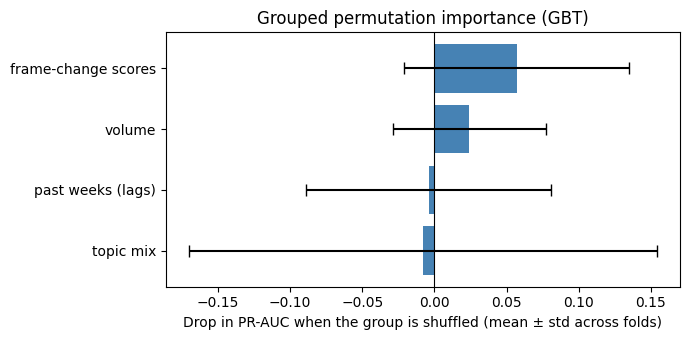

In [33]:
import matplotlib.pyplot as plt

plot_data = importance_summary.sort_values("mean")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(plot_data.index, plot_data["mean"], xerr=plot_data["std"], color="steelblue", capsize=4)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Drop in PR-AUC when the group is shuffled (mean ± std across folds)")
ax.set_title("Grouped permutation importance (GBT)")
plt.tight_layout()
plt.show()

#### Check one feature at a time
This shows why we shuffle by group. Shuffling one at a time makes every drop small when features overlap. We use scikit-learn's permutation_importance (scoring="average_precision" is its name for PR-AUC).

In [34]:
from sklearn.inspection import permutation_importance

single_rows = []
for fold_num, (train_rows, test_rows) in enumerate(folds, start=1):
    train_df = df.loc[train_rows]
    test_df = df.loc[test_rows]

    # PR-AUC can't be calculated without any shifts, so skip that fold
    if test_df["label"].sum() == 0:
        continue

    model = make_models()["Gradient-Boosted Trees"]
    model.fit(train_df[FEATURES], train_df["label"])

    result = permutation_importance(
        model, test_df[FEATURES], test_df["label"],
        scoring="average_precision", n_repeats=N_REPEATS, random_state=RANDOM_SEED,
    )

    for feature, drop in zip(FEATURES, result.importances_mean):
        single_rows.append({"fold": fold_num, "feature": feature, "pr_auc_drop": drop})

single = pd.DataFrame(single_rows)
single.groupby("feature")["pr_auc_drop"].agg(["mean", "std"]).sort_values("mean", ascending=False).round(3)

,mean,std
feature,,
issue_share,0.013,0.028
log_orig_per_day,0.006,0.012
shift_score,0.004,0.008
topic_biden,0.003,0.118
lag1_shift,0.001,0.034
topic_trump,0.001,0.024
lag2_shift,0.000,0.049
topic_harris,0.000,0.000
noise_missing,0.000,0.000


### What feature importance shows

**The frame-change scores matter most.** When we shuffled the frame-change scores (how much the topics changed from last week), PR-AUC dropped by 0.057 on average. It dropped in 4 of 5 folds, and in fold 1 it went up a little instead. Fold 1 trained on only 35 rows, so the model had the least to learn from there.

**Volume helps a little.** Shuffling volume (how much people tweeted about the issue) lowered PR-AUC by 0.024 on average, in 4 of 5 folds. The drops are small which means the model doesn't use volume very much.

**The model doesn't depend on the past weeks (lags) or the topic mix.** Both groups average a drop close to zero. Their drops also flip between positive and negative from fold to fold. A negative drop means the score went up when we shuffled the group which tells us the model wasn't using the group in a helpful way, or the test fold was too small. The topic mix varies the most with +0.26 in fold 4 and −0.18 in fold 5. Fold 4 has only 1 shift, so where that one row lands in the ranking can move the score a lot. This is also the same fold that influenced most of the gain in the ablation.

**No group's importance is consistent across folds.** For every group, the standard deviation is bigger than the average drop. The frame-change scores are the strongest indicator.

**Why we shuffled by group.** Shuffling the whole group at once keeps the model from using the other correlated features in that group, so the drop shows how much the model depends on the whole group. Many of our features are correlated (they measure almost the same thing). When one correlated feature is shuffled, the model can still use the others, so its importance looks lower than it is. When we shuffled one feature at a time, every drop was small (the largest was issue_share at 0.013) and several were negative.

**How this fits with the ablation.** The ablation showed that adding the topic features (Group B) raised PR-AUC in most folds. Permutation importance shows that the frame-change scores mattered most. The topic mix mattered most in fold 4 which drove most of the ablation gain. Both checks show that the past weeks (lags) do not help.

# Sensitivity analysis

How much do our results change when we change one part of the solution? We check two parts of the main model (GBT with all 17 features):
1. **The GBT settings (hyperparameters):** the 12 settings from the tuning grid.
2. **The yes/no rule:** how many issues we predict as a shift each week.

The ablation already showed how the results change with the features, so we don't repeat that here.

### GBT settings

We train GBT with each of the 12 settings from the tuning grid and score it on the same 5 outer folds. This is not tuning. We chose the main model's settings before seeing these scores, and we won't switch to a different setting because of them (that would be picking on the test weeks). We only want to see how much the test scores change across settings.

If the scores change less across settings than they vary across folds, the results don't depend much on the settings.

In [35]:
# The 12 GBT settings from the tuning grid
gbt_settings = ParameterGrid(PARAM_GRIDS["Gradient-Boosted Trees"])

setting_rows = []
for settings in gbt_settings:
    for fold_num, (train_rows, test_rows) in enumerate(folds, start=1):
        train_df = df.loc[train_rows]
        test_df = df.loc[test_rows]

        # Make an untrained GBT and apply these settings
        model = make_models()["Gradient-Boosted Trees"]
        model.set_params(**settings)
        model.fit(train_df[FEATURES], train_df["label"])

        # Score the outer test weeks with the same one-per-week rule
        scores = shift_scores(model, test_df[FEATURES])
        predictions = top_per_week(test_df, scores)
        fold_scores = score_fold(test_df["label"], predictions, scores)

        setting_rows.append({
            "max_depth": settings["max_depth"],
            "learning_rate": settings["learning_rate"],
            "min_samples_leaf": settings["min_samples_leaf"],
            "fold": fold_num,
            **fold_scores,
        })

settings_results = pd.DataFrame(setting_rows)

# One row per setting: mean and std across the 5 folds
SETTING_COLS = ["max_depth", "learning_rate", "min_samples_leaf"]
settings_summary = (
    settings_results.groupby(SETTING_COLS)
    .agg(
        pr_auc_mean=("pr_auc", "mean"),
        pr_auc_std=("pr_auc", "std"),
        f1_mean=("f1", "mean"),
    )
    .sort_values("pr_auc_mean", ascending=False)
    .round(2)
)
settings_summary

pr_auc_mean  pr_auc_std  f1_mean
max_depth learning_rate min_samples_leaf                                  
3         0.10          5                        0.55        0.30     0.35
                        3                        0.45        0.32     0.28
2         0.05          5                        0.40        0.20     0.28
          0.10          5                        0.38        0.16     0.28
3         0.05          5                        0.37        0.16     0.28
2         0.05          3                        0.37        0.15     0.28
3         0.05          3                        0.36        0.12     0.28
2         0.10          3                        0.35        0.14     0.22
3         0.10          10                       0.34        0.12     0.17
          0.05          10                       0.33        0.11     0.17
2         0.05          10                       0.32        0.09     0.23
          0.10          10                       0.30        0.07     0.15

#### How big is the change across settings?
The main model's row should match the earlier results (PR-AUC 0.38 ± 0.16).

In [36]:
# The settings our main model uses
MAIN_SETTINGS = (2, 0.1, 5)
main_row = settings_summary.loc[MAIN_SETTINGS]

lowest = settings_summary["pr_auc_mean"].min()
highest = settings_summary["pr_auc_mean"].max()

print(f"Main model (max_depth=2, learning_rate=0.1, min_samples_leaf=5): "
      f"PR-AUC {main_row['pr_auc_mean']:.2f} ± {main_row['pr_auc_std']:.2f}")
print(f"Mean PR-AUC across the 12 settings: {lowest:.2f} to {highest:.2f} "
      f"(gap {highest - lowest:.2f})")
print(f"Main model's std across folds: {main_row['pr_auc_std']:.2f}")

Main model (max_depth=2, learning_rate=0.1, min_samples_leaf=5): PR-AUC 0.38 ± 0.16
Mean PR-AUC across the 12 settings: 0.30 to 0.55 (gap 0.25)
Main model's std across folds: 0.16


#### Which setting matters most?
For each setting, we average PR-AUC over every value of the other two settings.

In [37]:
# Average PR-AUC for each value of one setting
# (averaged over all values of the other two settings)
for setting in SETTING_COLS:
    print(settings_results.groupby(setting)["pr_auc"].mean().round(2))
    print()

max_depth
2    0.35
3    0.40
Name: pr_auc, dtype: float64

learning_rate
0.05    0.36
0.10    0.40
Name: pr_auc, dtype: float64

min_samples_leaf
3     0.38
5     0.42
10    0.32
Name: pr_auc, dtype: float64



#### PR-AUC for each setting, by fold
Each gray line is one setting. The blue line is the main model. If the gray lines move up and down together, the fold (which weeks are tested) affects the score more than the settings do.

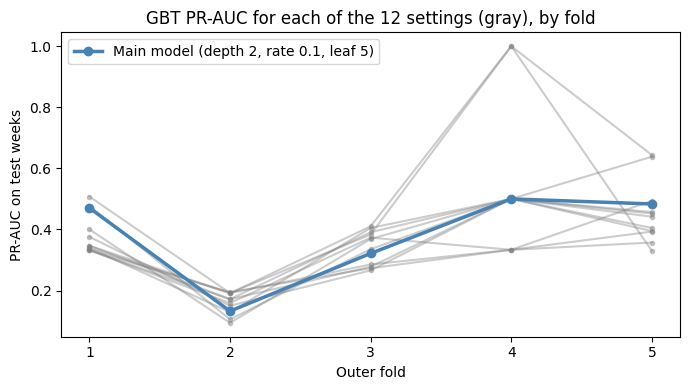

In [38]:
# One row per setting, one column per fold
per_fold_settings = settings_results.pivot_table(
    index=SETTING_COLS, columns="fold", values="pr_auc"
)

fig, ax = plt.subplots(figsize=(7, 4))

# One gray line per setting
for settings, row in per_fold_settings.iterrows():
    ax.plot(row.index, row.values, color="gray", alpha=0.4, marker="o", markersize=3)

# The main model's settings in blue
main_line = per_fold_settings.loc[MAIN_SETTINGS]
ax.plot(main_line.index, main_line.values, color="steelblue", linewidth=2.5,
        marker="o", label="Main model (depth 2, rate 0.1, leaf 5)")

ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("Outer fold")
ax.set_ylabel("PR-AUC on test weeks")
ax.set_title("GBT PR-AUC for each of the 12 settings (gray), by fold")
ax.legend()
plt.tight_layout()
plt.show()

#### PR-AUC for each setting in each fold
The same numbers as the plot in a table. With 1 shift, PR-AUC is 1 ÷ the shift’s rank. Across the 12 settings, the shift was ranked 1st, 2nd, or 3rd (1.0, 0.50, or 0.33).

In [39]:
# PR-AUC for each setting in each fold
settings_results.pivot_table(index=SETTING_COLS, columns="fold", values="pr_auc").round(2)

fold                                         1     2     3     4     5
max_depth learning_rate min_samples_leaf                              
2         0.05          3                 0.34  0.13  0.40  0.50  0.46
                        5                 0.40  0.09  0.37  0.50  0.64
                        10                0.33  0.16  0.37  0.33  0.39
          0.10          3                 0.38  0.15  0.27  0.50  0.45
                        5                 0.47  0.13  0.32  0.50  0.48
                        10                0.35  0.19  0.29  0.33  0.36
3         0.05          3                 0.33  0.17  0.39  0.50  0.39
                        5                 0.48  0.11  0.34  0.50  0.44
                        10                0.33  0.19  0.27  0.33  0.49
          0.10          3                 0.34  0.19  0.41  1.00  0.33
                        5                 0.51  0.19  0.38  1.00  0.64
                        10                0.35  0.17  0.28  0.50  0.40

In [40]:
# Mean PR-AUC for each setting without fold 4:
no_fold4 = settings_results[settings_results["fold"] != 4]
print(no_fold4.groupby(SETTING_COLS)["pr_auc"].mean().sort_values(ascending=False).round(2))
print()

# Average PR-AUC for each value of one setting, without fold 4
for setting in SETTING_COLS:
    print(no_fold4.groupby(setting)["pr_auc"].mean().round(2))
    print()

max_depth  learning_rate  min_samples_leaf
3          0.10           5                   0.43
2          0.05           5                   0.38
           0.10           5                   0.35
3          0.05           5                   0.34
2          0.05           3                   0.33
3          0.05           10                  0.32
                          3                   0.32
           0.10           3                   0.32
2          0.05           10                  0.31
           0.10           3                   0.31
3          0.10           10                  0.30
2          0.10           10                  0.30
Name: pr_auc, dtype: float64

max_depth
2    0.33
3    0.34
Name: pr_auc, dtype: float64

learning_rate
0.05    0.33
0.10    0.33
Name: pr_auc, dtype: float64

min_samples_leaf
3     0.32
5     0.37
10    0.31
Name: pr_auc, dtype: float64



### 2. How many shifts we predict each week

The yes/no rule (top_per_week) predicts the highest-scoring issue in each week as a shift. Here we try 1, 2, and 3 per week. With up to 5 issues per week, that predicts about 20%, 40%, or 60% of rows as shifts. The real shift rate is 16%.

- **PR-AUC stays the same** for every option, because it only uses the order of the scores, not the yes/no calls.
- **Best possible recall** is the highest recall the rule allows, even if the ranking were perfect. For example, if a week has 3 shifts and we predict 1, at least 2 are missed.

We include Baseline 2 to check whether GBT still scores above it under each option.

In [41]:
SHIFTS_PER_WEEK_OPTIONS = [1, 2, 3]

# Train GBT once per fold and keep its scores. The rule only changes how we
# turn scores into yes/no, so we don't need to train again for each option.
fold_outputs = []
for train_rows, test_rows in folds:
    train_df = df.loc[train_rows]
    test_df = df.loc[test_rows]

    model = make_models()["Gradient-Boosted Trees"]
    model.fit(train_df[FEATURES], train_df["label"])

    fold_outputs.append({
        "test_df": test_df,
        "Gradient-Boosted Trees": shift_scores(model, test_df[FEATURES]),
        "Baseline: biggest shift scores": test_df["shift_score"].to_numpy(),
    })

rule_rows = []
for shifts_per_week in SHIFTS_PER_WEEK_OPTIONS:
    for fold_num, output in enumerate(fold_outputs, start=1):
        test_df = output["test_df"]

        # Best possible recall: each week, the rule can catch at most
        # shifts_per_week shifts, even if the ranking is perfect
        shifts_by_week = test_df.groupby("week_idx")["label"].sum()
        catchable = shifts_by_week.clip(upper=shifts_per_week).sum()
        best_recall = catchable / shifts_by_week.sum()

        for model_name in ["Gradient-Boosted Trees", "Baseline: biggest shift scores"]:
            scores = output[model_name]
            predictions = top_per_week(test_df, scores, shifts_per_week)
            fold_scores = score_fold(test_df["label"], predictions, scores)

            rule_rows.append({
                "model": model_name,
                "shifts_per_week": shifts_per_week,
                "fold": fold_num,
                **fold_scores,
                "best_possible_recall": best_recall,
            })

rule_results = pd.DataFrame(rule_rows)

# Mean across the 5 folds
rule_results.groupby(["model", "shifts_per_week"])[
    ["precision", "recall", "f1", "best_possible_recall", "pr_auc"]
].mean().round(2)

precision  recall    f1  \
model                          shifts_per_week                            
Baseline: biggest shift scores 1                     0.20    0.31  0.20   
                               2                     0.12    0.36  0.16   
                               3                     0.18    0.77  0.28   
Gradient-Boosted Trees         1                     0.25    0.41  0.28   
                               2                     0.25    0.65  0.33   
                               3                     0.22    0.79  0.32   

                                                best_possible_recall  pr_auc  
model                          shifts_per_week                                
Baseline: biggest shift scores 1                                0.67    0.27  
                               2                                0.84    0.27  
                               3                                0.92    0.27  
Gradient-Boosted Trees         1                                0.67    0.38  
                               2                                0.84    0.38  
                               3                                0.92    0.38

## What the sensitivity analysis shows

### GBT settings

**With all 5 folds, the settings change PR-AUC more than the folds do.** Across the 12 settings, mean PR-AUC ranges from 0.30 to 0.55 (a gap of 0.25). This is larger than the main model's standard deviation across folds (0.16). The main model (max_depth=2, learning_rate=0.1, min_samples_leaf=5) scores 0.38, which is 4th of 12.

**Most of that gap comes from one row in fold 4.** With 1 shift, PR-AUC is 1 ÷ the shift’s rank. Across the 12 settings, the shift was ranked 1st, 2nd, or 3rd (1.0, 0.50, or 0.33). Only the two highest-scoring settings (max_depth=3, learning_rate=0.1, min_samples_leaf=3 or 5) ranked it 1st. This is also why they have the largest standard deviations (0.32 and 0.30). Without fold 4, mean PR-AUC ranges from 0.30 to 0.43 (a gap of 0.13), which is smaller than the fold-to-fold standard deviation.

**min_samples_leaf is the only setting with an effect that holds without fold 4.** min_samples_leaf is the fewest rows allowed in each branch of a tree. min_samples_leaf=5 scores best with or without fold 4. With all folds, the four lowest-scoring settings all use 10. With only 35 to 115 training rows and few shifts, requiring 10 rows per branch keeps the trees from separating small groups of shift rows. max_depth (0.35 vs. 0.40) and learning_rate (0.36 vs. 0.40) seem to matter with all folds, but without fold 4 both values of each average about the same (0.33).

**The test weeks matter as much as the settings.** In the plot, the gray lines mostly move up and down together. Every setting scores low in fold 2 (0.09 to 0.19), so fold 2 is hard no matter which settings we use.

**We keep the main model's settings.** Without fold 4, max_depth=3, learning_rate=0.1, min_samples_leaf=5 still scores highest (0.43 vs. 0.35 for the main model), mostly from folds 1 and 5. But we found this only after looking at the test weeks, and nested cross-validation picked different settings in different folds. Switching to it would be picking on the test weeks (optimistic bias), the same reason we kept Group C in the ablation. The difference (0.08) is also smaller than how much the main model's scores vary across folds (0.16).

### Number of shifts predicted each week

**Predicting 2 per week gives GBT its best F1.** Going from 1 to 2 per week raises recall from 0.41 to 0.65 while precision stays at 0.25, so F1 goes from 0.28 to 0.33. Going to 3 per week raises recall to 0.79 but lowers precision to 0.22, and F1 stays about the same (0.32).

**The 1-per-week rule limits recall.** Because shifts often happen in the same week, predicting 1 per week can identify at most 67% of a fold's shifts on average across folds, even with a perfect ranking (best possible recall). This rises to 84% with 2 per week and 92% with 3. GBT reaches 0.41 of the possible 0.67 at 1 per week and 0.65 of 0.84 at 2 per week.

**GBT stays above Baseline 2 under every option, but the gap shrinks at 3 per week.** F1 is 0.28 vs. 0.20 at 1 per week, 0.33 vs. 0.16 at 2, and 0.32 vs. 0.28 at 3. At 3 per week we predict about 60% of rows as shifts, so even the baseline catches most shifts (recall 0.77).

**Precision stays close to the shift rate.** GBT's precision (0.22 to 0.25) is only a little above the shift rate in the test weeks (17 of 97 rows, about 18%). That is the precision we would expect from picking rows by chance.

**PR-AUC does not change** (0.38 for GBT, 0.27 for Baseline 2), because it uses only the order of the scores.

**We keep 1 per week as the main rule.** We chose it before seeing test scores, based on the shift rate (16% of 5 issues is about 1 per week). Switching to 2 because it scored best would be picking on the test weeks. We report 2 per week as a sensitivity finding.

# Tradeoffs

We check two tradeoffs:
1. **Precision vs. recall:** predicting more shifts per week catches more real shifts (higher recall) but adds more wrong predictions (lower precision).
2. **Training data size vs. score:** we keep the test weeks fixed and train on fewer or more of the most recent weeks.

In [42]:
# Predict 1 to 5 shifts per week. 5 per week means every row is predicted as a shift.
TRADEOFF_OPTIONS = [1, 2, 3, 4, 5]
TRADEOFF_MODELS = ["Gradient-Boosted Trees", "Baseline: biggest shift scores"]

tradeoff_rows = []
for model_name in TRADEOFF_MODELS:
    for shifts_per_week in TRADEOFF_OPTIONS:

        # Put every fold's test weeks into one pile.
        # The rule ranks issues inside each week, so scores from
        # different folds are never compared with each other.
        all_labels = []
        all_predictions = []
        for output in fold_outputs:
            test_df = output["test_df"]
            predictions = top_per_week(test_df, output[model_name], shifts_per_week)
            all_labels.extend(test_df["label"])
            all_predictions.extend(predictions)

        all_labels = np.array(all_labels)
        all_predictions = np.array(all_predictions)

        tradeoff_rows.append({
            "model": model_name,
            "shifts_per_week": shifts_per_week,
            "predicted_shifts": all_predictions.sum(),
            "shifts_caught": ((all_predictions == 1) & (all_labels == 1)).sum(),
            "precision": precision_score(all_labels, all_predictions),
            "recall": recall_score(all_labels, all_predictions),
            "f1": f1_score(all_labels, all_predictions),
        })

tradeoff = pd.DataFrame(tradeoff_rows)
tradeoff.round(2)

,model,shifts_per_week,predicted_shifts,shifts_caught,precision,recall,f1
0,Gradient-Boosted Trees,1,20,5,0.25,0.29,0.27
1,Gradient-Boosted Trees,2,40,10,0.25,0.59,0.35
2,Gradient-Boosted Trees,3,60,13,0.22,0.76,0.34
3,Gradient-Boosted Trees,4,80,15,0.19,0.88,0.31
4,Gradient-Boosted Trees,5,97,17,0.18,1.00,0.30
5,Baseline: biggest shift scores,1,20,4,0.20,0.24,0.22
6,Baseline: biggest shift scores,2,40,5,0.12,0.29,0.18
7,Baseline: biggest shift scores,3,60,11,0.18,0.65,0.29
8,Baseline: biggest shift scores,4,80,15,0.19,0.88,0.31
9,Baseline: biggest shift scores,5,97,17,0.18,1.00,0.30


### Tradeoff Plot

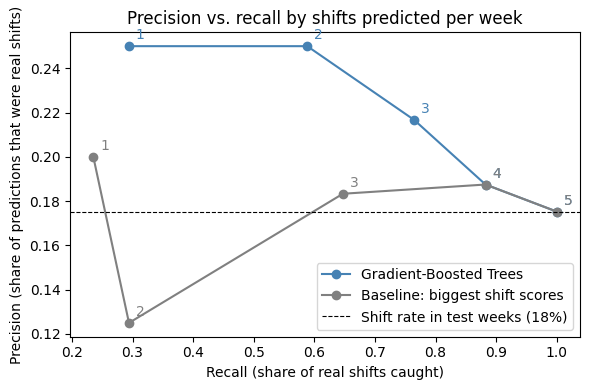

In [43]:
# Shift rate in all test weeks (the precision we'd get by chance)
pooled_labels = []
for output in fold_outputs:
    pooled_labels.extend(output["test_df"]["label"])
shift_rate = np.mean(pooled_labels)

fig, ax = plt.subplots(figsize=(6, 4))
for model_name, color in [("Gradient-Boosted Trees", "steelblue"),
                          ("Baseline: biggest shift scores", "gray")]:
    rows = tradeoff[tradeoff["model"] == model_name]
    ax.plot(rows["recall"], rows["precision"], marker="o", color=color, label=model_name)

    # Write the number of shifts predicted per week next to each point
    for _, row in rows.iterrows():
        ax.annotate(str(row["shifts_per_week"]), (row["recall"], row["precision"]),
                    textcoords="offset points", xytext=(5, 5), color=color)

ax.axhline(shift_rate, color="black", linestyle="--", linewidth=0.8,
           label=f"Shift rate in test weeks ({shift_rate:.0%})")
ax.set_xlabel("Recall (share of real shifts caught)")
ax.set_ylabel("Precision (share of predictions that were real shifts)")
ax.set_title("Precision vs. recall by shifts predicted per week")
ax.legend()
plt.tight_layout()
plt.show()

### Training Data Size vs. Score

In [44]:
# Test fold: list of training window sizes (number of most recent weeks)
TRAIN_WINDOW_SIZES = {3: [5, 10, 15], 5: [5, 10, 15, 20, 23]}

size_rows = []
for fold_num, window_sizes in TRAIN_WINDOW_SIZES.items():
    train_rows, test_rows = folds[fold_num - 1]
    test_df = df.loc[test_rows]

    # The training weeks this fold is allowed to use, oldest to newest
    allowed_weeks = np.sort(df.loc[train_rows, "week_idx"].unique())

    for n_weeks in window_sizes:
        # Keep only the most recent n_weeks before the gap week
        recent_weeks = allowed_weeks[-n_weeks:]
        train_df = df[df["week_idx"].isin(recent_weeks)]

        # A model can't learn "shift" if the training weeks have no shifts, so skip
        if train_df["label"].nunique() < 2:
            continue

        model = make_models()["Gradient-Boosted Trees"]
        model.fit(train_df[FEATURES], train_df["label"])

        scores = shift_scores(model, test_df[FEATURES])
        predictions = top_per_week(test_df, scores)
        fold_scores = score_fold(test_df["label"], predictions, scores)

        size_rows.append({
            "test_fold": fold_num,
            "train_weeks": n_weeks,
            "train_rows": len(train_df),
            "train_shifts": train_df["label"].sum(),
            "pr_auc": fold_scores["pr_auc"],
            "f1": fold_scores["f1"],
        })

training_size = pd.DataFrame(size_rows)
training_size.round(2)

,test_fold,train_weeks,train_rows,train_shifts,pr_auc,f1
0,3,5,25,3,0.13,0.00
1,3,10,50,12,0.27,0.57
2,3,15,75,13,0.32,0.57
3,5,5,25,3,0.53,0.25
4,5,10,50,6,0.45,0.25
5,5,15,75,13,0.33,0.25
6,5,20,100,17,0.36,0.25
7,5,23,115,18,0.48,0.25


### What the tradeoffs show

##### Precision vs. recall
Predicting more shifts per week raises recall and lowers precision. For GBT, going from 1 to 4 per week raises recall from 0.29 to 0.88 and lowers precision from 0.25 to 0.19. 2 per week doubles recall (0.29 to 0.59) with no loss in precision. GBT beats Baseline 2 on both measures at 1 to 3 per week. F1 can favor predicting every row as a shift. Predicting all rows as shifts gives F1 = 0.30, higher than GBT under our main rule (0.27), even though its precision equals the shift rate (0.18). This is one reason PR-AUC is our main metric.(Pooled over all 97 test rows, so the numbers are different from the fold averages in the sensitivity table.)

##### Training data size vs. score
We kept the test weeks fixed and trained on fewer or more of the most recent weeks. More data helped in fold 3 but not in fold 5. In fold 3, PR-AUC rose from 0.13 to 0.32, mostly when training shifts went from 3 to 12. In fold 5, there was no pattern (0.33 to 0.53), and the smallest window scored highest. With only 3–4 shifts per test fold, and smaller windows also being more recent, we can't measure the effect of training size with this data.

# Failure analysis

We look at the rows where the main model (GBT, 1 shift predicted per week) was wrong:
- **False positive:** predicted a shift, but there was no shift.
- **False negative:** missed a real shift.

First we build one table of every test row, then check which kinds of rows fail most often, then pick specific rows to study.

#### Error Table

In [45]:
# Build one table with every test row, the GBT score, and whether the prediction was right
error_parts = []
for fold_num, output in enumerate(fold_outputs, start=1):
    test_df = output["test_df"].copy()
    test_df["fold"] = fold_num
    test_df["gbt_score"] = output["Gradient-Boosted Trees"]

    # Rank inside the week: 1 = highest score that week
    test_df["rank_in_week"] = test_df.groupby("week_idx")["gbt_score"].rank(
        ascending=False, method="first"
    ).astype(int)

    # Main rule: the top issue each week is predicted as a shift
    test_df["predicted"] = top_per_week(test_df, test_df["gbt_score"])

    # How many real shifts happened that week (across all issues)
    test_df["shifts_in_week"] = test_df.groupby("week_idx")["label"].transform("sum")

    error_parts.append(test_df)

errors = pd.concat(error_parts, ignore_index=True)

# Name each row's result
errors["result"] = "true negative"
errors.loc[(errors["predicted"] == 1) & (errors["label"] == 1), "result"] = "true positive"
errors.loc[(errors["predicted"] == 1) & (errors["label"] == 0), "result"] = "false positive"
errors.loc[(errors["predicted"] == 0) & (errors["label"] == 1), "result"] = "false negative"

errors["result"].value_counts()

result
true negative     65
false positive    15
false negative    12
true positive      5
Name: count, dtype: int64

#### Which kind of rows fail most often

In [46]:
# Conditions (1 = yes, 0 = no) for the failure categories we want to check
errors["collection_gap"] = (errors["days_with_data"] <= 3).astype(int)
errors["multi_shift_week"] = (errors["shifts_in_week"] >= 2).astype(int)
errors["no_shift_week"] = (errors["shifts_in_week"] == 0).astype(int)

# For each condition: how many shifts were in those rows, and how many did GBT get right?
condition_rows = []
for condition in ["collection_gap", "noise_missing", "multi_shift_week", "no_shift_week"]:
    for value in [1, 0]:
        part = errors[errors[condition] == value]
        condition_rows.append({
            "condition": condition,
            "value": value,
            "rows": len(part),
            "shifts": part["label"].sum(),
            "true_positives": (part["result"] == "true positive").sum(),
            "false_negatives": (part["result"] == "false negative").sum(),
            "false_positives": (part["result"] == "false positive").sum(),
        })

pd.DataFrame(condition_rows)

,condition,value,rows,shifts,true_positives,false_negatives,false_positives
0,collection_gap,1,20,5,1,4,3
1,collection_gap,0,77,12,4,8,12
2,noise_missing,1,8,1,0,1,2
3,noise_missing,0,89,16,5,11,13
4,multi_shift_week,1,20,12,3,9,1
5,multi_shift_week,0,77,5,2,3,14
6,no_shift_week,1,52,0,0,0,11
7,no_shift_week,0,45,17,5,12,4


#### Every failed row

In [47]:
show_cols = [
    "fold", "issue", "week_idx", "label", "predicted", "gbt_score", "rank_in_week",
    "shifts_in_week", "days_with_data", "orig_tweet_count", "noise_missing", "shift_score",
]
failures = errors[errors["result"].isin(["false positive", "false negative"])]
failures.sort_values(["fold", "week_idx", "rank_in_week"])[show_cols].round(3)

,fold,issue,week_idx,label,predicted,gbt_score,rank_in_week,shifts_in_week,days_with_data,orig_tweet_count,noise_missing,shift_score
12,1,foreign_policy,11,0,1,0.880,1,1,6,78140,0,0.349
4,1,democracy,11,1,0,0.834,2,1,6,86048,0,0.294
17,1,immigration,12,1,0,0.560,2,4,3,32504,0,0.363
13,1,foreign_policy,12,1,0,0.024,3,4,3,17993,0,0.395
1,1,abortion,12,1,0,0.002,5,4,3,4956,0,0.416
14,1,foreign_policy,13,0,1,0.159,1,0,2,3528,0,0.376
19,1,immigration,14,0,1,0.307,1,2,7,65010,0,0.336
3,1,abortion,14,1,0,0.105,2,2,7,12107,1,0.374
11,1,economy,14,1,0,0.008,5,2,7,78959,0,0.266
24,2,democracy,15,0,1,0.768,1,0,7,30279,0,0.310


### Using SHAP to find out why the model scored the rows this way?

SHAP values show how much each feature pushed a row's score up (+) or down (−) from a starting score (the expected value). The starting score plus all of a row's SHAP values equals the model's score for that row. Because SHAP values add up this way, we add them within each feature group, the same four groups used in permutation importance. This handles the correlated features (features that measure almost the same thing).

The scores are in log-odds (the model's raw score before it is turned into a probability). Log-odds keep the same order as the probabilities, so they explain each row's rank in its week.

In [49]:
import shap

shap_parts = []
for fold_num, (train_rows, test_rows) in enumerate(folds, start=1):
    train_df = df.loc[train_rows]
    test_df = df.loc[test_rows]

    # Train the same main model as before (same settings and random seed)
    model = make_models()["Gradient-Boosted Trees"]
    model.fit(train_df[FEATURES], train_df["label"])

    # Check: this model gives the same scores as the main model in fold_outputs
    same_scores = np.allclose(
        shift_scores(model, test_df[FEATURES]),
        fold_outputs[fold_num - 1]["Gradient-Boosted Trees"],
    )

    # SHAP values: how much each feature pushed this row's score up (+) or down (-)
    explainer = shap.TreeExplainer(model)
    values = explainer.shap_values(test_df[FEATURES])
    values = pd.DataFrame(values, columns=FEATURES, index=test_df.index)
    starting_score = float(np.ravel(explainer.expected_value)[0])

    # Check: starting score + all SHAP values = the model's score (in log-odds)
    total = starting_score + values.sum(axis=1)
    adds_up = np.allclose(total, model.decision_function(test_df[FEATURES]))

    print(f"Fold {fold_num}: same scores as main model: {same_scores}, "
          f"SHAP values add up: {adds_up}")

    # Add the SHAP values within each feature group
    fold_shap = pd.DataFrame(index=test_df.index)
    for group_name, group_features in FEATURE_GROUPS.items():
        fold_shap[group_name] = values[group_features].sum(axis=1)

    fold_shap["starting_score"] = starting_score
    fold_shap["fold"] = fold_num
    fold_shap["issue"] = test_df["issue"]
    fold_shap["week_idx"] = test_df["week_idx"]
    shap_parts.append(fold_shap)

shap_table = pd.concat(shap_parts, ignore_index=True)

# Join the SHAP group sums to the failed rows
failure_shap = errors[errors["result"].isin(["false positive", "false negative"])].merge(
    shap_table, on=["fold", "issue", "week_idx"]
)

group_cols = list(FEATURE_GROUPS.keys())
failure_shap[
    ["fold", "issue", "week_idx", "result", "rank_in_week", "starting_score"] + group_cols
].sort_values(["fold", "week_idx"]).round(2)

Fold 1: same scores as main model: True, SHAP values add up: True
Fold 2: same scores as main model: True, SHAP values add up: True
Fold 3: same scores as main model: True, SHAP values add up: True
Fold 4: same scores as main model: True, SHAP values add up: True
Fold 5: same scores as main model: True, SHAP values add up: True


,fold,issue,week_idx,result,rank_in_week,starting_score,volume,frame-change scores,topic mix,past weeks (lags)
2,1,democracy,11,false negative,2,-4.97,-0.41,4.74,0.84,1.41
4,1,foreign_policy,11,false positive,1,-4.97,-0.71,4.37,1.86,1.44
0,1,abortion,12,false negative,5,-4.97,-0.35,0.64,0.68,-2.25
5,1,foreign_policy,12,false negative,3,-4.97,0.22,1.39,1.72,-2.06
7,1,immigration,12,false negative,2,-4.97,-0.50,1.94,2.34,1.44
6,1,foreign_policy,13,false positive,1,-4.97,0.75,3.22,1.61,-2.27
1,1,abortion,14,false negative,2,-4.97,0.07,4.16,0.81,-2.21
3,1,economy,14,false negative,5,-4.97,-0.29,-2.27,1.76,0.91
8,1,immigration,14,false positive,1,-4.97,-0.22,1.18,1.75,1.44
9,2,democracy,15,false positive,1,-3.55,-0.49,3.17,1.88,0.19


### Three example rows for Failure Analysis

In [50]:
# The three failed rows we study below: (issue, week)
EXAMPLES = [("economy", 27), ("abortion", 26), ("abortion", 14)]

example_rows = []
for issue, week in EXAMPLES:
    row = failure_shap[(failure_shap["issue"] == issue) & (failure_shap["week_idx"] == week)]
    example_rows.append(row)

example_cols = [
    "fold", "issue", "week_idx", "result", "gbt_score", "rank_in_week",
    "shifts_in_week", "orig_tweet_count", "noise_missing", "starting_score",
] + group_cols
pd.concat(example_rows)[example_cols].round(3)

,fold,issue,week_idx,result,gbt_score,rank_in_week,shifts_in_week,orig_tweet_count,noise_missing,starting_score,volume,frame-change scores,topic mix,past weeks (lags)
22,5,economy,27,false negative,0.362,2,4,16548,0,-2.172,0.518,0.846,-1.016,1.257
19,4,abortion,26,false positive,0.974,1,0,2196,0,-2.348,-0.393,3.016,3.094,0.266
1,1,abortion,14,false negative,0.105,2,2,12107,1,-4.968,0.068,4.156,0.808,-2.206
